In [1]:
import pandas as pd, glob
df = pd.concat([pd.read_csv(f, encoding="latin-1", on_bad_lines="skip") for f in glob.glob("data/*.csv")])
df.head()

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,13/08/16,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,13/08/16,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,13/08/16,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,13/08/16,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,13/08/16,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values("Date").reset_index(drop=True)
df.head()

C:\Users\MY PC\AppData\Local\Temp\ipykernel_24696\2831496088.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,2016-08-13,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,2016-08-13,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,2016-08-13,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,2016-08-13,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,2016-08-13,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
def elo_expected(r_home, r_away, home_adv=60):
    return 1/(1+10**((r_away - (r_home + home_adv))/400))

In [4]:
def compute_elo(data, K=20, home_adv=60, carry=1.0, mov=False):
    ratings, home_elo, away_elo = {}, [], []
    season = None
    for _, row in data.iterrows():
        d = row["Date"]
        s = d.year if d.month >= 8 else d.year - 1
        if s != season:
            ratings = {t: 1500 + carry * (r - 1500) for t, r in ratings.items()}
            season = s
        h, a = row["HomeTeam"], row["AwayTeam"]
        rh, ra = ratings.get(h, 1500), ratings.get(a,1500)
        home_elo.append(rh)
        away_elo.append(ra)
        actual = {"H": 1, "D": 0.5, "A": 0}[row["FTR"]]
        mult = 1
        if mov: 
            gd = abs(row["FTHG"] - row["FTAG"])
            mult = 1 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        change = K * mult * (actual - elo_expected(rh, ra, home_adv))
        ratings[h], ratings[a] = rh + change, ra - change
    return home_elo, away_elo, ratings

df["home_elo"], df["away_elo"], ratings = compute_elo(df, K=40)

C:\Users\MY PC\AppData\Local\Temp\ipykernel_24696\1057776759.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["home_elo"], df["away_elo"], ratings = compute_elo(df, K=40)


In [5]:
sorted(ratings.items(), key=lambda x: x[1], reverse=True)[:6]

[('Arsenal', 1809.2462026222877),
 ('Man City', 1772.1335486552437),
 ('Man United', 1731.3636701433986),
 ('Bournemouth', 1691.4452421016395),
 ('Aston Villa', 1656.8070029237867),
 ('Liverpool', 1635.6421036744864)]

In [6]:
home = pd.DataFrame({"Date": df["Date"], "Team": df["HomeTeam"], "GF": df["FTHG"], "GA": df["FTAG"], "Shots": df["HS"], "SOT": df["HST"], "Result": df["FTR"].map({"H": 3, "D": 1, "A": 0})})
away = pd.DataFrame({"Date": df["Date"], "Team": df["AwayTeam"], "GF": df["FTAG"], "GA": df["FTHG"], "Shots": df["AS"], "SOT": df["AST"], "Result": df["FTR"].map({"A": 3, "D": 1, "H": 0})})
teams = pd.concat([home, away]).sort_values("Date").reset_index(drop=True)
teams.head()

,Date,Team,GF,GA,Shots,SOT,Result
0,2016-08-13,Burnley,0,1,10,3,0
1,2016-08-13,Tottenham,1,1,13,4,1
2,2016-08-13,Leicester,1,2,18,5,0
3,2016-08-13,Sunderland,1,2,7,3,0
4,2016-08-13,Stoke,1,1,12,1,1


In [7]:
for col in ["GF", "GA", "Shots", "SOT", "Result"]:
    for n in [5, 10]:
        teams[f"{col}_last{n}"] = teams.groupby("Team")[col].transform(lambda s: s.shift(1).rolling(n).mean())
teams.head(10)

,Date,Team,GF,GA,Shots,SOT,Result,GF_last5,GF_last10,GA_last5,GA_last10,Shots_last5,Shots_last10,SOT_last5,SOT_last10,Result_last5,Result_last10
0,2016-08-13,Burnley,0,1,10,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-08-13,Tottenham,1,1,13,4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-08-13,Leicester,1,2,18,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-08-13,Sunderland,1,2,7,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-08-13,Stoke,1,1,12,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2016-08-13,Watford,1,1,5,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2016-08-13,West Brom,1,0,13,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2016-08-13,Swansea,1,0,17,9,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2016-08-13,Southampton,1,1,24,6,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2016-08-13,Middlesbrough,1,1,12,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
teams[teams["Team"] == "Arsenal"].tail(10)

,Date,Team,GF,GA,Shots,SOT,Result,GF_last5,GF_last10,GA_last5,GA_last10,Shots_last5,Shots_last10,SOT_last5,SOT_last10,Result_last5,Result_last10
7396,2026-03-01,Arsenal,2,1,12,5,3,2.8,2.3,0.8,1.0,13.4,14.0,5.2,4.9,2.2,1.9
7419,2026-03-04,Arsenal,1,0,7,2,3,2.4,2.1,1.0,1.0,13.0,13.0,4.6,4.7,2.2,1.9
7429,2026-03-14,Arsenal,2,0,25,7,3,2.0,1.9,1.0,0.8,11.2,12.5,4.0,4.4,2.2,1.9
7467,2026-04-11,Arsenal,1,2,15,3,0,2.2,2.1,0.8,0.8,14.8,14.1,5.0,4.7,2.6,2.1
7494,2026-04-19,Arsenal,1,2,9,3,0,2.0,2.2,0.8,1.0,15.8,14.1,4.8,4.7,2.4,2.0
7513,2026-04-25,Arsenal,1,0,11,4,3,1.4,2.1,1.0,0.9,13.6,13.5,4.0,4.6,1.8,2.0
7527,2026-05-02,Arsenal,3,0,18,9,3,1.2,1.8,0.8,0.9,13.4,13.2,3.8,4.2,1.8,2.0
7554,2026-05-10,Arsenal,1,0,15,4,3,1.6,1.8,0.8,0.9,15.6,13.4,5.2,4.6,1.8,2.0
7575,2026-05-18,Arsenal,1,0,13,3,3,1.4,1.8,0.8,0.8,13.6,14.2,4.6,4.8,1.8,2.2
7584,2026-05-24,Arsenal,2,1,17,7,3,1.4,1.7,0.4,0.6,13.2,14.5,4.6,4.7,2.4,2.4


In [9]:
features = [c for c in teams.columns if "_last" in c]
home_form = teams[["Date", "Team"] + features].rename(columns={f: "home_" + f for f in features})
away_form = teams[["Date", "Team"] + features].rename(columns={f: "away_" + f for f in features})
matches = df[["Date", "HomeTeam", "AwayTeam", "FTR", "home_elo", "away_elo"]]
matches = matches.merge(home_form, left_on=["Date", "HomeTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.merge(away_form, left_on=["Date", "AwayTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.dropna()
matches.head()

,Date,HomeTeam,AwayTeam,FTR,home_elo,away_elo,home_GF_last5,home_GF_last10,home_GA_last5,home_GA_last10,...,away_GF_last5,away_GF_last10,away_GA_last5,away_GA_last10,away_Shots_last5,away_Shots_last10,away_SOT_last5,away_SOT_last10,away_Result_last5,away_Result_last10
100,2016-11-05,Bournemouth,Sunderland,A,1491.082077,1373.466930,1.8,1.2,1.0,1.4,...,0.8,0.7,2.2,2.0,8.4,8.9,2.0,2.4,0.2,0.2
101,2016-11-05,Burnley,Crystal Palace,H,1476.982429,1459.776950,1.0,0.8,1.0,1.3,...,1.4,1.4,2.2,1.6,14.4,14.6,4.4,4.5,0.8,1.1
102,2016-11-05,Chelsea,Everton,H,1584.339096,1538.456536,2.2,2.1,0.6,0.9,...,1.0,1.5,1.0,0.8,13.2,14.3,4.2,5.8,1.0,1.8
103,2016-11-05,Man City,Middlesbrough,D,1592.187855,1471.120258,1.8,2.4,1.0,0.9,...,0.8,0.9,0.8,1.1,9.2,9.2,3.0,2.6,1.0,1.0
104,2016-11-05,West Ham,Stoke,D,1451.187891,1491.779614,0.6,1.0,1.2,1.9,...,1.8,1.2,0.6,1.7,13.2,12.0,4.8,3.5,2.2,1.2


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_cols = ["home_elo", "away_elo"]
train = matches[matches["Date"] < "2025-08-01"]
test = matches[matches["Date"] >= "2025-08-01"]
X_train, y_train = train[X_cols], train["FTR"]
X_test, y_test = test[X_cols], test["FTR"]

In [11]:
from sklearn.metrics import log_loss

def evaluate(cols, data=None):
    if data is None:
        data = matches
    fit_part = data[data["Date"] < "2024-08-01"]
    val = data[(data["Date"] >= "2024-08-01") & (data["Date"] < "2025-08-01")]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(fit_part[cols], fit_part["FTR"])
    acc = accuracy_score(val["FTR"], m.predict(val[cols]))
    ll = log_loss(val["FTR"], m.predict_proba(val[cols]), labels=m.classes_)
    return round(acc, 3), round(ll, 4)

I compared the model with multiple and different features and in a 5-10 game margin. Out of everything, using only Elo proved to give the best result which is why I'm using Elo only.I tested it with the 24-25 dataframe.

In [12]:
elo = ["home_elo", "away_elo"]
def cols(stats, n):
    return [f"{s}_{c}_last{n}" for s in ["home", "away"] for c in stats]

options = {
    "current": elo + cols(["GF", "GA", "Shots", "Result"], 5), "+ SOT": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 5), "last 10": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 10), "5 and 10": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 5) + cols(["GF", "GA", "Shots", "SOT", "Result"], 10), "Elo only": elo,
}
for name, c in options.items():
    print(name, evaluate(c))

current (0.541, 0.9856)
+ SOT (0.546, 0.9856)
last 10 (0.519, 0.9963)
5 and 10 (0.524, 1.0024)
Elo only (0.538, 0.9857)


K = 40 gives the best log loss. Home advantage is basically pointless. Pulling rating towards 1500 and margin of victory both made things worse. final tuning for elo is K = 40 and home_adv = 60

In [13]:
def evaluate_elo(**params):
    h, a, _ = compute_elo(df, **params)
    elo_df = df[["Date", "HomeTeam", "AwayTeam"]].assign(home_elo=h, away_elo=a)
    data = matches.drop(columns=["home_elo", "away_elo"]).merge(elo_df, on=["Date", "HomeTeam", "AwayTeam"])
    return evaluate(["home_elo", "away_elo"], data)

for K in [10, 20, 30, 40]:
    for ha in [40, 60, 80, 100]:
        print(K, ha, evaluate_elo(K=K, home_adv=ha))

10 40 (0.511, 1.0151)
10 60 (0.514, 1.0156)
10 80 (0.516, 1.0163)
10 100 (0.516, 1.0173)
20 40 (0.532, 0.9928)
20 60 (0.532, 0.993)
20 80 (0.532, 0.9933)
20 100 (0.532, 0.9938)
30 40 (0.543, 0.9867)
30 60 (0.541, 0.9867)
30 80 (0.541, 0.9868)
30 100 (0.538, 0.9869)
40 40 (0.538, 0.9859)
40 60 (0.538, 0.9857)
40 80 (0.538, 0.9855)
40 100 (0.541, 0.9854)


In [14]:
for K in [40, 50, 60, 80]:
    print(K, evaluate_elo(K=K, home_adv=60))

40 (0.538, 0.9857)
50 (0.535, 0.9868)
60 (0.538, 0.9887)
80 (0.532, 0.9936)


In [15]:
best_K, best_ha = 40, 60
for carry in [1.0, 0.9, 0.8, 0.7]:
    for mov in [False, True]:
        print(carry, mov, evaluate_elo(K=best_K, home_adv=best_ha, carry=carry, mov=mov))

1.0 False (0.538, 0.9857)
1.0 True (0.532, 0.9898)
0.9 False (0.538, 0.986)
0.9 True (0.532, 0.9901)
0.8 False (0.538, 0.9867)
0.8 True (0.535, 0.9909)
0.7 False (0.535, 0.9879)
0.7 True (0.535, 0.992)


In [16]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Model accuracy:", accuracy_score(y_test, pred))
print("Always-home baseline:", (y_test == "H").mean())

Model accuracy: 0.5
Always-home baseline: 0.4263157894736842


In [17]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
print("Random forest accuracy:", accuracy_score(y_test, rf.predict(X_test)))

Random forest accuracy: 0.48947368421052634


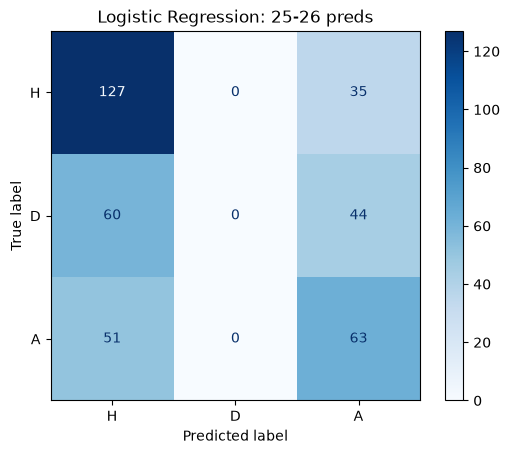

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["H", "D", "A"]
cm = confusion_matrix(y_test, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Logistic Regression: 25-26 preds")
plt.show()

In [19]:
fit_part = train[train["Date"] < "2024-08-01"]
val = train[train["Date"] >= "2024-08-01"]
tmp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
tmp.fit(fit_part[X_cols], fit_part["FTR"])
val_probs = pd.DataFrame(tmp.predict_proba(val[X_cols]), columns=tmp.classes_, index=val.index)
for m in [0, 0.05, 0.10, 0.15, 0.20]:
    close = (val_probs["H"] - val_probs["A"]).abs() < m
    picks = val_probs.idxmax(axis=1).where(~close, "D")
    print(m, round(accuracy_score(val["FTR"], picks), 3), (picks == "D").sum(), "draws")

0 0.538 0 draws
0.05 0.519 30 draws
0.1 0.522 61 draws
0.15 0.495 87 draws
0.2 0.481 109 draws


The model wasn't predicting any draws. I tested calling a draw when the two teams' win probability was withn a margin. everything above 0 reduced accuracy and the draw calls were very few to the point of being redundant. this made me keep best_m as 0.

In [20]:
best_m = 0.0
test_probs = pd.DataFrame(model.predict_proba(X_test), columns=model.classes_, index=X_test.index)
close = (test_probs["H"] - test_probs["A"]).abs() < best_m
final_picks = test_probs.idxmax(axis=1).where(~close, "D")
print("Accuracy with draw rule:", accuracy_score(y_test, final_picks))
print("Draws predicted:", (final_picks == "D").sum())

Accuracy with draw rule: 0.5
Draws predicted: 0


In [21]:
results = test[["Date", "HomeTeam", "AwayTeam", "FTR"]].copy()
results["Pick"] = final_picks
results[["P(H)", "P(D)", "P(A)"]] = test_probs[["H", "D", "A"]].round(2)
results.tail(10)

,Date,HomeTeam,AwayTeam,FTR,Pick,P(H),P(D),P(A)
3790,2026-05-24,Nott'm Forest,Bournemouth,D,A,0.33,0.24,0.43
3791,2026-05-24,Man City,Aston Villa,A,H,0.69,0.19,0.13
3792,2026-05-24,Sunderland,Chelsea,H,H,0.41,0.25,0.34
3793,2026-05-24,Liverpool,Brentford,D,H,0.51,0.24,0.26
3794,2026-05-24,Tottenham,Everton,H,A,0.33,0.25,0.42
3795,2026-05-24,Crystal Palace,Arsenal,A,A,0.19,0.21,0.60
3796,2026-05-24,Burnley,Wolves,D,A,0.36,0.27,0.37
3797,2026-05-24,Brighton,Man United,A,A,0.35,0.24,0.41
3798,2026-05-24,Fulham,Newcastle,H,H,0.42,0.25,0.33
3799,2026-05-24,West Ham,Leeds,H,A,0.35,0.25,0.40


In [22]:
draw_calls = final_picks == "D"
print("Draw calls:", draw_calls.sum())
print("Correct draw calls:", (y_test[draw_calls] == "D").sum())

Draw calls: 0
Correct draw calls: 0
